In [3]:
%pip install rasterio

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [5]:
import glob, os, numpy as np, rasterio, pandas as pd

ROOT = r"C:\Users\User\Downloads\EuroSAT_MS"
files = glob.glob(os.path.join(ROOT, "**", "*.tif"), recursive=True)
print("files found:", len(files))

rows = []
for f in files:
    with rasterio.open(f) as src:
        rows.append(dict(path=f, label=os.path.basename(os.path.dirname(f)),
                         bands=src.count, h=src.height, w=src.width,
                         dtype=src.dtypes[0], crs=str(src.crs),
                         x0=src.transform.c, y0=src.transform.f))
df = pd.DataFrame(rows)
print(df.label.value_counts())
print(df[["bands", "h", "w", "dtype"]].drop_duplicates())

os.makedirs("data_card", exist_ok=True)
df.to_csv("data_card/tile_index.csv", index=False)

rng = np.random.default_rng(0)
sample = [rasterio.open(f).read() for f in rng.choice(files, 200, replace=False)]
a = np.stack(sample).astype("float64")
print("min / max / mean:", a.min(), a.max(), a.mean())

files found: 27000
label
AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Residential             3000
SeaLake                 3000
Highway                 2500
PermanentCrop           2500
Industrial              2500
River                   2500
Pasture                 2000
Name: count, dtype: int64
   bands   h   w   dtype
0     13  64  64  uint16
min / max / mean: 1.0 28001.0 1429.0661486816407


## Spatial-block split


In [6]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.3 MB 10.5 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.3 MB 11.4 MB/s eta 0:00:01
   -------------------------------- ------- 6.8/8.3 MB 12.0 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 11.4 MB/s eta 0:00:00
  Attempting uninstall: narwhals
    Found existing installation: narwhals 1.46.0
    Uninstalling narwhals-1.46.0:
      Successfully uninstalled narwhals-1.46.0
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.46.1 requires protobuf<7,>=3.20, but you have protobuf 7.34.0 which is incompatible.


In [7]:
from rasterio.warp import transform
from sklearn.model_selection import GroupShuffleSplit

df["lon"] = np.nan
df["lat"] = np.nan
for crs, g in df.groupby("crs"):        # one conversion per UTM zone
    lo, la = transform(crs, "EPSG:4326", g.x0.tolist(), g.y0.tolist())
    df.loc[g.index, "lon"] = lo
    df.loc[g.index, "lat"] = la

BLOCK = 0.5   # degrees, roughly 50 km
df["block"] = (df.lon // BLOCK).astype(int).astype(str) + "_" + (df.lat // BLOCK).astype(int).astype(str)
print("blocks:", df.block.nunique())

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1)
tv_idx, te_idx = next(gss.split(df, groups=df.block))
tv = df.iloc[tv_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.125, random_state=1)
tr_i, va_i = next(gss2.split(tv, groups=tv.block))

df["split"] = "train"
df.loc[tv.index[va_i], "split"] = "val"
df.loc[df.index[te_idx], "split"] = "test"

assert df.groupby("block").split.nunique().max() == 1   # leakage check
print(pd.crosstab(df.label, df.split))
df[["path", "label", "block", "split"]].to_csv("data_card/splits.csv", index=False)

blocks: 948
split                 test  train  val
label                                 
AnnualCrop             537   1805  658
Forest                 528   2226  246
HerbaceousVegetation   646   2074  280
Highway                492   1764  244
Industrial             443   1844  213
Pasture                205   1397  398
PermanentCrop          348   1973  179
Residential            437   2330  233
River                  434   1811  255
SeaLake                814   1832  354


In [8]:
import os, numpy as np, rasterio
from PIL import Image

sp = pd.read_csv("data_card/splits.csv")
RGB = (3, 2, 1)   # B04, B03, B02 (zero-based) - confirm band order in the docs

def to_uint8(arr, lo=0.0, hi=3000.0):
    return (np.clip((arr - lo) / (hi - lo), 0, 1) * 255).astype("uint8")

for r in sp.itertuples():
    out_dir = os.path.join("data", r.split, r.label)
    os.makedirs(out_dir, exist_ok=True)
    with rasterio.open(r.path) as src:
        arr = src.read([i + 1 for i in RGB]).astype("float32")
    img = to_uint8(np.moveaxis(arr, 0, -1))
    name = os.path.splitext(os.path.basename(r.path))[0] + ".png"
    Image.fromarray(img).save(os.path.join(out_dir, name))
print(sp.split.value_counts())

split
train    19056
test      4884
val       3060
Name: count, dtype: int64


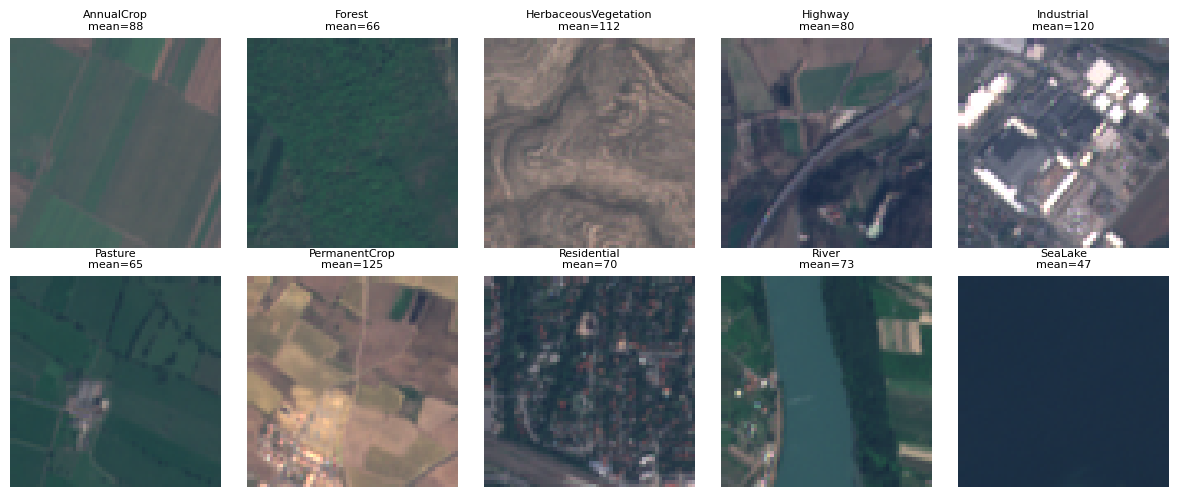

In [9]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np, os, random

random.seed(0)
classes = sorted(os.listdir("data/train"))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, c in zip(axes.ravel(), classes):
    f = random.choice(os.listdir(f"data/train/{c}"))
    im = np.array(Image.open(f"data/train/{c}/{f}"))
    ax.imshow(im); ax.set_title(f"{c}\nmean={im.mean():.0f}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig("data_card/sample_tiles.png", dpi=150); plt.show()

In [10]:
import rasterio, numpy as np, pandas as pd

df = pd.read_csv("data_card/tile_index.csv")
with rasterio.open(df.path.iloc[0]) as s:
    print("pixel size:", s.res, "| CRS:", s.crs)
    print("tags:", s.tags())
    print("band descriptions:", s.descriptions)

rng = np.random.default_rng(0)
a = np.stack([rasterio.open(p).read() for p in rng.choice(df.path, 200, replace=False)]).astype("float64")
print(pd.DataFrame({"band": range(1, 14),
                    "min": a.min((0, 2, 3)),
                    "mean": a.mean((0, 2, 3)).round(0),
                    "max": a.max((0, 2, 3))}))

pixel size: (10.00570688714736, 9.994088099999352) | CRS: EPSG:32635
tags: {'AREA_OR_POINT': 'Area'}
band descriptions: (None, None, None, None, None, None, None, None, None, None, None, None, None)
    band    min    mean      max
0      1  889.0  1344.0   3699.0
1      2  171.0  1115.0  28000.0
2      3  159.0  1046.0  27443.0
3      4  141.0   967.0  28000.0
4      5  190.0  1207.0  11792.0
5      6  161.0  1992.0  13311.0
6      7  135.0  2362.0  11945.0
7      8   98.0  2285.0  28001.0
8      9   45.0   710.0   2355.0
9     10    3.0    12.0     56.0
10    11    6.0  1822.0  12367.0
11    12    1.0  1137.0  10239.0
12    13   95.0  2578.0  13609.0


In [11]:
X = a.transpose(1, 0, 2, 3).reshape(13, -1)[:, ::10]
corr = np.corrcoef(X)
print("corr with file band 8 -> band 9:", corr[7, 8].round(2), "| band 13:", corr[7, 12].round(2))

corr with file band 8 -> band 9: 0.78 | band 13: 0.98
